## Section 2 – Task 2: day-ahead hourly energy forecast per station

At the end of a day we want the next day's energy use for every station, hour by hour. We first set up the evaluation: a chronological 70/30 split and the naive "average weekday" baseline. We then train a model on lag and calendar features and score it on exactly the same test hours.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.utils.capture import capture_output

### 2.1 Station-hour table

Everything below only needs one table with one row per station and hour: `Station Name`, `Hour` (time-zone aware) and `Energy (kWh)`, where an empty value means the station was out of service. The next cell is the only one that knows where that table comes from, so a different cleaning pipeline can be swapped in by replacing it.

For now it comes from `hourly_panel` in `ev_charging_palo_alto.ipynb` (Section 1). That notebook is run once and the result is cached in `station_hours.pkl`; delete the file to rebuild after the cleaning changes.

In [2]:
# --- Swappable cleaning step: must produce `panel` with the three columns below ---
CACHE = Path("station_hours.pkl")
if not CACHE.exists():
    with capture_output():  # hide the cleaning notebook's own prints and plots
        get_ipython().run_line_magic("run", "ev_charging_palo_alto.ipynb")
    hourly_panel.to_pickle(CACHE)

panel = pd.read_pickle(CACHE)[["Station Name", "Hour", "Energy (kWh)"]].copy()

# Contract that the rest of the notebook relies on
assert panel["Hour"].dt.tz is not None, "Hour must be time-zone aware"
assert not panel.duplicated(["Station Name", "Hour"]).any(), "one row per station and hour"
assert (panel["Energy (kWh)"].dropna() >= 0).all(), "energy cannot be negative"

print("Station-hours:", len(panel), "| stations:", panel["Station Name"].nunique())
print("Out-of-service hours (empty):", panel["Energy (kWh)"].isna().sum())

Station-hours: 1533155 | stations: 46
Out-of-service hours (empty): 14665


In [3]:
# Days, hours and weekdays follow the local Palo Alto clock, since a forecast "day" is a local day
LOCAL_TZ = "America/Los_Angeles"
local = panel["Hour"].dt.tz_convert(LOCAL_TZ)
panel["Date"] = local.dt.tz_localize(None).dt.normalize()
panel["Hour_Of_Day"] = local.dt.hour
panel["Weekday"] = local.dt.dayofweek  # 0 = Monday

### 2.2 Chronological 70/30 split

The data is not shuffled. We take the day before which 70% of all in-service station-hours fall, and cut there for every station at once: everything earlier is training data, everything from that day on is the test set. One shared cut-off date means no model ever sees information from the test period, and cutting at midnight keeps the test set made of whole days, which is what a day-ahead forecast predicts.

In [4]:
in_service = panel.dropna(subset=["Energy (kWh)"])
CUTOFF = in_service["Date"].quantile(0.70).normalize()

train = panel[panel["Date"] < CUTOFF].copy()
test = panel[panel["Date"] >= CUTOFF].copy()

n_train, n_test = train["Energy (kWh)"].notna().sum(), test["Energy (kWh)"].notna().sum()
print("Cut-off day (first test day):", CUTOFF.date())
print(f"Train: {train['Date'].min().date()} to {train['Date'].max().date()}, {n_train} station-hours ({n_train / (n_train + n_test):.1%})")
print(f"Test : {test['Date'].min().date()} to {test['Date'].max().date()}, {n_test} station-hours ({n_test / (n_train + n_test):.1%})")

new_stations = sorted(set(test["Station Name"]) - set(train["Station Name"]))
print(f"Stations in test with no training history: {len(new_stations)}")
print(new_stations)

assert train["Date"].max() < CUTOFF <= test["Date"].min()
assert abs(n_train / (n_train + n_test) - 0.70) < 0.01

Cut-off day (first test day): 2019-04-23
Train: 2011-07-29 to 2019-04-22, 1062214 station-hours (70.0%)
Test : 2019-04-23 to 2021-01-01, 456276 station-hours (30.0%)
Stations in test with no training history: 13
['PALO ALTO CA / SHERMAN 1', 'PALO ALTO CA / SHERMAN 11', 'PALO ALTO CA / SHERMAN 14', 'PALO ALTO CA / SHERMAN 15', 'PALO ALTO CA / SHERMAN 17', 'PALO ALTO CA / SHERMAN 2', 'PALO ALTO CA / SHERMAN 3', 'PALO ALTO CA / SHERMAN 4', 'PALO ALTO CA / SHERMAN 5', 'PALO ALTO CA / SHERMAN 6', 'PALO ALTO CA / SHERMAN 7', 'PALO ALTO CA / SHERMAN 8', 'PALO ALTO CA / SHERMAN 9']


### 2.3 Baseline: the average weekday

For each station, the baseline predicts an hour with the average energy that station used at that weekday and hour in the training set. So next Monday 9–10 am is predicted as the average of all training Mondays 9–10 am at that station. Out-of-service hours are left out of the averages.

In [5]:
KEYS = ["Station Name", "Weekday", "Hour_Of_Day"]

def fit_baseline(train):
    return train.groupby(KEYS)["Energy (kWh)"].mean().rename("Baseline")

def evaluate(y_true, y_pred):
    err = y_pred - y_true
    return pd.Series({"MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean())})

profile = fit_baseline(train)
test = test.join(profile, on=KEYS)

# Score only hours where the station was in service and has a training history
scored = test.dropna(subset=["Energy (kWh)", "Baseline"])
print(f"Scored test station-hours: {len(scored)} of {len(test)}")

# Check: the baseline for one station/weekday/hour equals the plain training average
s, w, h = scored.iloc[0][KEYS]
by_hand = train.loc[(train["Station Name"] == s) & (train["Weekday"] == w) & (train["Hour_Of_Day"] == h), "Energy (kWh)"].mean()
assert np.isclose(profile.loc[(s, w, h)], by_hand)
assert np.allclose(evaluate(pd.Series([1.0, 3.0]), pd.Series([2.0, 1.0])), [1.5, np.sqrt(2.5)])

Scored test station-hours: 454108 of 459284


In [6]:
baseline_overall = evaluate(scored["Energy (kWh)"], scored["Baseline"])
print("Baseline on the test set (kWh per station-hour):")
print(baseline_overall.round(4).to_string())

baseline_by_station = (
    scored.groupby("Station Name")[["Energy (kWh)", "Baseline"]]
    .apply(lambda g: evaluate(g["Energy (kWh)"], g["Baseline"]))
    .assign(Mean_Energy=scored.groupby("Station Name")["Energy (kWh)"].mean())
    .sort_values("MAE", ascending=False)
)
display(baseline_by_station.round(3))

Baseline on the test set (kWh per station-hour):
MAE     1.4979
RMSE    2.1501


,MAE,RMSE,Mean_Energy
Station Name,,,
PALO ALTO CA / WEBSTER #2,2.358,2.980,1.658
PALO ALTO CA / WEBSTER #1,2.336,2.998,2.278
PALO ALTO CA / HAMILTON #2,2.133,2.755,2.630
PALO ALTO CA / WEBSTER #3,2.123,2.809,1.399
PALO ALTO CA / HIGH #1,2.086,2.763,1.210
PALO ALTO CA / HIGH #3,1.997,2.707,1.787
PALO ALTO CA / TED THOMPSON #1,1.989,2.558,1.688
PALO ALTO CA / HIGH #2,1.833,2.517,1.321
PALO ALTO CA / CAMBRIDGE #1,1.803,2.339,1.427


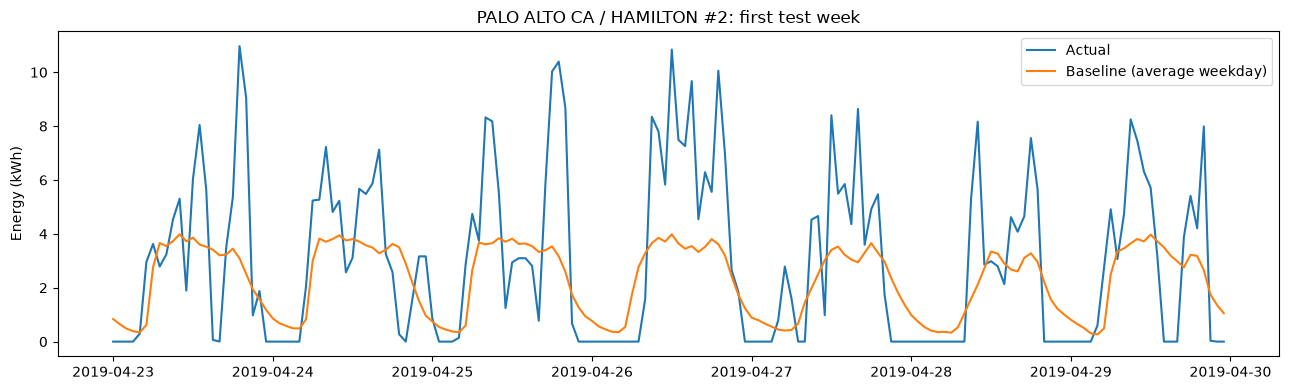

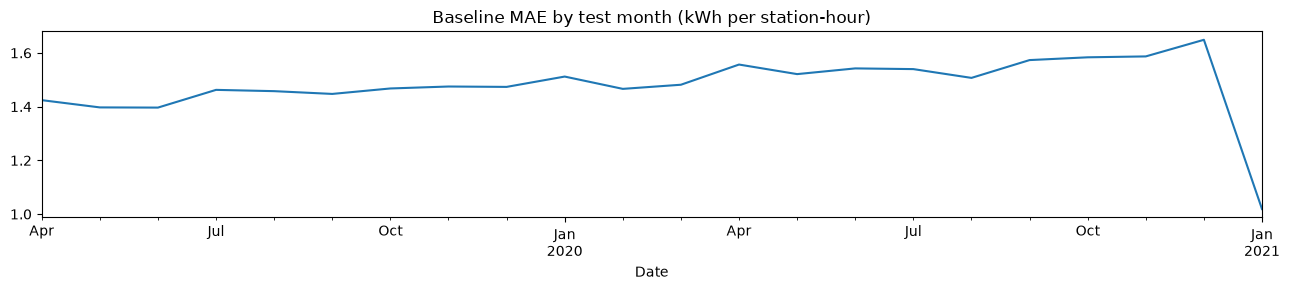

In [7]:
# First full test week at the station with the most test energy
station = scored.groupby("Station Name")["Energy (kWh)"].sum().idxmax()
week = scored[(scored["Station Name"] == station) & (scored["Date"] < scored["Date"].min() + pd.Timedelta(days=7))]
x = week["Hour"].dt.tz_convert(LOCAL_TZ)

plt.figure(figsize=(13, 4))
plt.plot(x, week["Energy (kWh)"], label="Actual")
plt.plot(x, week["Baseline"], label="Baseline (average weekday)")
plt.title(f"{station}: first test week")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

# Error by month shows where the baseline breaks down
monthly = scored.groupby(scored["Date"].dt.to_period("M"))[["Energy (kWh)", "Baseline"]].apply(
    lambda g: evaluate(g["Energy (kWh)"], g["Baseline"]))
monthly["MAE"].plot(figsize=(13, 3), title="Baseline MAE by test month (kWh per station-hour)")
plt.tight_layout()
plt.show()

### 2.4 Features

The forecast for day *D* is made at midnight, so a feature may only use what is known by the end of day *D-1*. Every lag is therefore counted in whole days back from the target hour: the same clock hour 1, 2, 7 and 14 days ago, the average of that hour over the last 7 days and over the last 4 same weekdays, and the station's average hourly energy yesterday and over the last week. In the test period these lags use actual observations from earlier test days, which is what the company would have at hand each midnight; the model itself is never refitted.

Calendar features are hour, weekday, month and US federal holidays. The baseline's own prediction and the station are also given to the model, so it starts from the average weekday and learns when to move away from it.

In [8]:
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.ensemble import HistGradientBoostingRegressor

TARGET = "Energy (kWh)"
DAY = pd.Timedelta(days=1)

def lookup(values, *keys):
    # Value for each row's keys; empty where that station/day/hour does not exist
    return values.reindex(pd.MultiIndex.from_arrays(keys)).to_numpy()

def build_features(panel, profile):
    df = panel[["Station Name", "Hour", "Date", "Hour_Of_Day", "Weekday", TARGET]].copy()
    station, date, hour = df["Station Name"], df["Date"], df["Hour_Of_Day"]

    # Lookups by local clock hour and by local day (averaging makes the two daylight-saving days safe)
    by_hour = df.groupby(["Station Name", "Date", "Hour_Of_Day"])[TARGET].mean()
    by_day = df.groupby(["Station Name", "Date"])[TARGET].mean()
    same_hour = pd.DataFrame({k: lookup(by_hour, station, date - k * DAY, hour)
                              for k in [1, 2, 3, 4, 5, 6, 7, 14, 21, 28]}, index=df.index)
    whole_day = pd.DataFrame({k: lookup(by_day, station, date - k * DAY) for k in range(1, 8)}, index=df.index)

    for k in [1, 2, 7, 14]:
        df[f"Lag_{k}d"] = same_hour[k]
    df["Hour_Mean_7d"] = same_hour[list(range(1, 8))].mean(axis=1)
    df["Hour_Mean_4w"] = same_hour[[7, 14, 21, 28]].mean(axis=1)
    df["Day_Mean_1d"] = whole_day[1]
    df["Day_Mean_7d"] = whole_day.mean(axis=1)

    df["Month"] = date.dt.month
    df["Is_Holiday"] = date.isin(USFederalHolidayCalendar().holidays(date.min(), date.max())).astype(int)
    df["Baseline"] = lookup(profile, station, df["Weekday"], hour)
    df["Station"] = station.astype("category")
    return df

FEATURES = ["Station", "Hour_Of_Day", "Weekday", "Month", "Is_Holiday", "Baseline",
            "Lag_1d", "Lag_2d", "Lag_7d", "Lag_14d", "Hour_Mean_7d", "Hour_Mean_4w", "Day_Mean_1d", "Day_Mean_7d"]

features = build_features(panel, profile)

# Check: no feature looks into the target day. Lag_1d must equal the same station and clock hour one day earlier.
row = features.loc[scored.index[5000]]
before = panel[(panel["Station Name"] == row["Station Name"]) & (panel["Date"] == row["Date"] - DAY)
               & (panel["Hour_Of_Day"] == row["Hour_Of_Day"])]
assert np.isclose(row["Lag_1d"], before[TARGET].mean(), equal_nan=True)
assert np.allclose(features.loc[scored.index, "Baseline"], scored["Baseline"])
display(features.loc[scored.index, FEATURES].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Hour_Of_Day,454108.0,11.495,6.922,0.0,5.000,11.000,17.000,23.000
Weekday,454108.0,2.997,1.998,0.0,1.000,3.000,5.000,6.000
Month,454108.0,7.068,3.183,1.0,5.000,7.000,10.000,12.000
Is_Holiday,454108.0,0.027,0.162,0.0,0.000,0.000,0.000,1.000
Baseline,454108.0,1.632,1.528,0.0,0.284,1.214,2.588,6.548
Lag_1d,454004.0,1.113,2.298,0.0,0.000,0.000,0.489,12.575
Lag_2d,453932.0,1.114,2.299,0.0,0.000,0.000,0.493,12.575
Lag_7d,453572.0,1.123,2.306,0.0,0.000,0.000,0.552,12.575
Lag_14d,453068.0,1.132,2.314,0.0,0.000,0.000,0.611,12.720
Hour_Mean_7d,454036.0,1.117,1.564,0.0,0.000,0.393,1.734,9.388


### 2.5 Model

One gradient-boosted tree model is trained for all stations together. Trees handle the non-linear mix of hour, weekday and recent demand, cope with the empty lags left by outages and new stations, and a shared model lets quiet stations borrow strength from busy ones. It is fitted with squared error, so it predicts the expected energy just like the baseline does. Settings are fixed in advance and were not tuned on the test set. Predictions below zero are set to zero.

In [9]:
is_train = (features["Date"] < CUTOFF) & features[TARGET].notna()

model = HistGradientBoostingRegressor(categorical_features="from_dtype", learning_rate=0.05, max_iter=300, random_state=0)
model.fit(features.loc[is_train, FEATURES], features.loc[is_train, TARGET])

# Same test rows as the baseline
scored["Model"] = model.predict(features.loc[scored.index, FEATURES]).clip(min=0)

results = pd.DataFrame({name: evaluate(scored[TARGET], scored[name]) for name in ["Baseline", "Model"]}).T
results["MAE change"] = results["MAE"] / results.loc["Baseline", "MAE"] - 1
results["RMSE change"] = results["RMSE"] / results.loc["Baseline", "RMSE"] - 1
print(f"Trained on {is_train.sum()} station-hours, scored on {len(scored)}")
display(results.style.format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "MAE change": "{:+.1%}", "RMSE change": "{:+.1%}"}))

Trained on 1062214 station-hours, scored on 454108


,MAE,RMSE,MAE change,RMSE change
Baseline,1.4979,2.1501,+0.0%,+0.0%
Model,1.1238,1.8153,-25.0%,-15.6%


In [10]:
# Per station: does the model win everywhere, or only on average?
def both(g):
    b, m = evaluate(g[TARGET], g["Baseline"]), evaluate(g[TARGET], g["Model"])
    return pd.Series({"Baseline_MAE": b["MAE"], "Model_MAE": m["MAE"], "Baseline_RMSE": b["RMSE"], "Model_RMSE": m["RMSE"]})

by_station = scored.groupby("Station Name")[[TARGET, "Baseline", "Model"]].apply(both)
by_station["MAE change"] = by_station["Model_MAE"] / by_station["Baseline_MAE"] - 1
print("Stations where the model has lower MAE :", (by_station["Model_MAE"] < by_station["Baseline_MAE"]).sum(), "of", len(by_station))
print("Stations where the model has lower RMSE:", (by_station["Model_RMSE"] < by_station["Baseline_RMSE"]).sum(), "of", len(by_station))
display(by_station.sort_values("MAE change").round(3))

# Before and after the COVID drop in demand
period = np.where(scored["Date"] < "2020-03-13", "Before 13 Mar 2020", "From 13 Mar 2020")
display(scored.groupby(period)[[TARGET, "Baseline", "Model"]].apply(both).round(3))

# The stations that opened after the cut-off: the baseline has nothing to say, the model can use their lags
new_rows = features[features["Station Name"].isin(new_stations) & (features["Date"] >= CUTOFF) & features[TARGET].notna()]
new_pred = pd.Series(model.predict(new_rows[FEATURES]).clip(min=0), index=new_rows.index)
print(f"New stations (not part of the comparison), {len(new_rows)} station-hours:")
print(evaluate(new_rows[TARGET], new_pred).round(4).to_string(), "| mean energy:", round(new_rows[TARGET].mean(), 4))

Stations where the model has lower MAE : 33 of 33
Stations where the model has lower RMSE: 33 of 33


,Baseline_MAE,Model_MAE,Baseline_RMSE,Model_RMSE,MAE change
Station Name,,,,,
PALO ALTO CA / MPL #3,0.310,0.094,0.498,0.334,-0.696
PALO ALTO CA / MPL #1,0.233,0.078,0.391,0.277,-0.667
PALO ALTO CA / MPL #2,0.355,0.130,0.560,0.425,-0.634
PALO ALTO CA / BRYANT #1,1.360,0.635,1.689,1.173,-0.533
PALO ALTO CA / CAMBRIDGE #2,1.563,0.915,2.001,1.488,-0.415
PALO ALTO CA / HIGH #1,2.086,1.245,2.763,2.016,-0.403
PALO ALTO CA / BRYANT #2,1.386,0.885,1.731,1.422,-0.362
PALO ALTO CA / WEBSTER #3,2.123,1.384,2.809,2.064,-0.348
PALO ALTO CA / WEBSTER #2,2.358,1.557,2.980,2.243,-0.340


,Baseline_MAE,Model_MAE,Baseline_RMSE,Model_RMSE
Before 13 Mar 2020,1.454,1.315,2.139,2.028
From 13 Mar 2020,1.555,0.878,2.164,1.498


New stations (not part of the comparison), 2168 station-hours:


MAE     0.3103
RMSE    1.0915 | mean energy: 0.2398


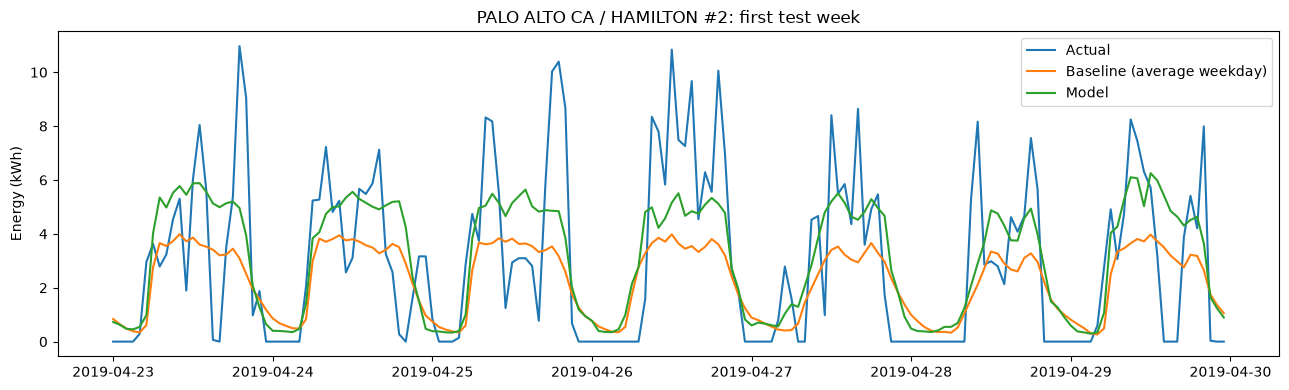

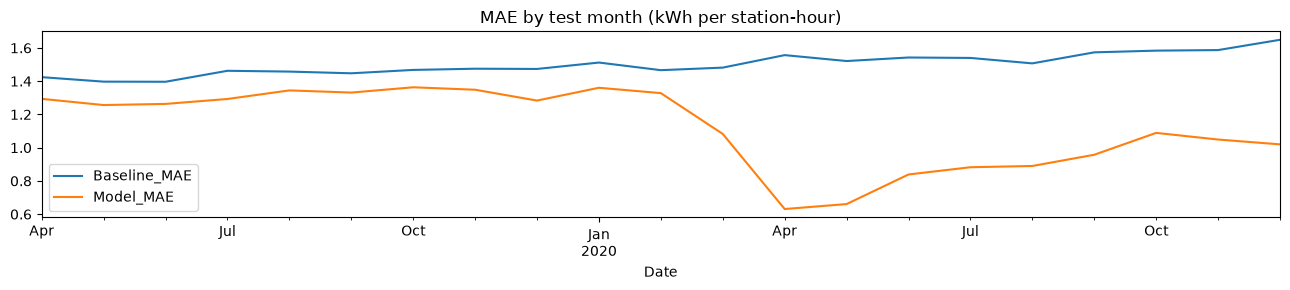

In [11]:
# Same station and week as in 2.3, now with the model
week = scored[(scored["Station Name"] == station) & (scored["Date"] < scored["Date"].min() + pd.Timedelta(days=7))]
x = week["Hour"].dt.tz_convert(LOCAL_TZ)

plt.figure(figsize=(13, 4))
plt.plot(x, week[TARGET], label="Actual")
plt.plot(x, week["Baseline"], label="Baseline (average weekday)")
plt.plot(x, week["Model"], label="Model")
plt.title(f"{station}: first test week")
plt.ylabel("Energy (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

monthly = scored.groupby(scored["Date"].dt.to_period("M"))[[TARGET, "Baseline", "Model"]].apply(both)
monthly[["Baseline_MAE", "Model_MAE"]].iloc[:-1].plot(figsize=(13, 3), title="MAE by test month (kWh per station-hour)")
plt.tight_layout()
plt.show()